In [7]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split 
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
X, y = load_iris(return_X_y=True) 

In [9]:
print(X.shape)
print(y.shape)

# print(X)
# print(y)

# s = dict()
# for i in y:
#     s[i] = s.get(i, 0)
#     s[i] += 1

# print(s)
print(np.bincount(y)) 

(150, 4)
(150,)
[50 50 50]


In [10]:
X_tr, X_t, y_tr, y_t = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

In [12]:
model = GaussianNB()
model.fit(X_tr, y_tr)
y_pred = model.predict(X_t)

In [13]:
# alr computed y_pred, avoid predicting again through model.score()
# model.score(X_t, y_t)

print(f"Accuracy: {accuracy_score(y_t, y_pred):.2%}")

Accuracy: 96.67%


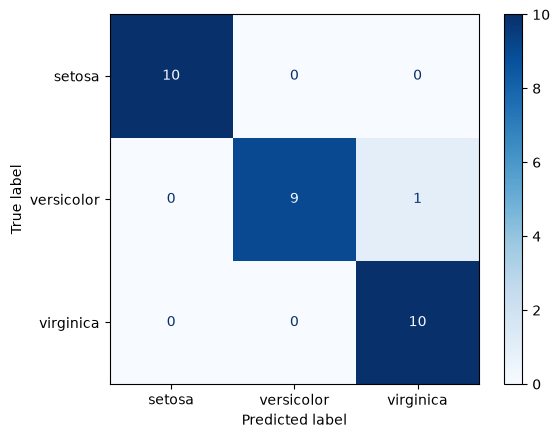

In [14]:
cm = confusion_matrix(y_t, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=load_iris().target_names)
disp.plot(cmap=plt.cm.Blues)
plt.show()


In [15]:
proba = model.predict_proba(X_t[:3])

print(model.classes_)  
print(proba)

[0 1 2]
[[1.00000000e+000 2.10423610e-020 1.24046690e-025]
 [8.47878473e-143 8.77457913e-002 9.12254209e-001]
 [2.60594992e-036 9.99999490e-001 5.10180517e-007]]


### grid search

Best parameters: {'var_smoothing': 1e-11}
Mean CV accuracy: 0.95
Held-out accuracy: 0.9666666666666667


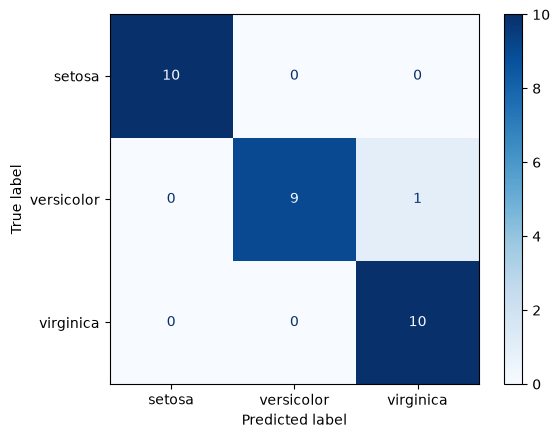

In [16]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold 
cv = StratifiedKFold(
    n_splits=5, 
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    GaussianNB(), 
    param_grid={
        "var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1],
    },
    scoring="accuracy",
    cv=cv,
)

search.fit(X_tr, y_tr)
print("Best parameters:", search.best_params_)
print("Mean CV accuracy:", search.best_score_)
print("Held-out accuracy:", search.score(X_t, y_t))

grid_pred = search.predict(X_t)
cm = confusion_matrix(y_t, grid_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=load_iris().target_names)
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [17]:
for params, score in zip(
    search.cv_results_["params"],
    search.cv_results_["mean_test_score"],
):
    print(params, f"{score:.2%}")

{'var_smoothing': 1e-11} 95.00%
{'var_smoothing': 1e-09} 95.00%
{'var_smoothing': 1e-07} 95.00%
{'var_smoothing': 1e-05} 95.00%
{'var_smoothing': 0.001} 95.00%
{'var_smoothing': 0.1} 92.50%
